In [ ]:
import numpy as np
import matplotlib.pyplot as plt

**Q2 (5 points).** Generate a synthetic 2-dimensional dataset composed of two correlated Gaussian features. Use NumPy for data generation. Visualize this dataset with scatter plots and discuss the correlation structure observed.


In [ ]:
def generate_dataset(num_samples=200, random_seed=42):
    """
    Generates a synthetic 2-dimensional dataset composed of two correlated Gaussian features

    Args:
        num_samples (int): Number of observations (integer >= 2).
        random_seed (int): Seed for reproducible results.

    Returns:
        data: numpy array of shape (num_samples, 2).
    """
    if not isinstance(num_samples, (int, np.integer)):
        raise TypeError("num_samples must be an integer.")

    if num_samples < 2:
        raise ValueError("atleast 2 samples are requried.")

    # feature means
    feature_averages = np.array([5.0, 10.0])

    # non diagonal elements must be positive in covariance matrix
    # for two positively correlated variables
    covariance_matrix = np.array([
        [3.0, 2.0],
        [2.0, 2.0]
    ])

    # random number generator
    rng = np.random.default_rng(random_seed)

    # generate dataset samples drawn from gaussian distribution
    data = rng.multivariate_normal(
        mean=feature_averages,
        cov=covariance_matrix,
        size=num_samples
    )

    return data


In [ ]:

def visualize_dataset(data):
    """
    Generate the scatter plot of the dataset.

    Args:
        data: numpy (num_samples, 2).
    """
    if data.ndim != 2 or data.shape[1] != 2:
        raise ValueError("dataset must have exactly 2 features.")

    if data.shape[0] < 2:
        raise ValueError("atleast 2 samples are required.")

    if not np.all(np.isfinite(data)):
        raise ValueError("dataset must contain only finite values.")

    # calculate the Karl Pearson correlation coefficient.
    corr_matrix = np.corrcoef(data, rowvar=False)
    correlation = corr_matrix[0, 1]

    # plot feature 1 against feature 2.
    plt.figure(figsize=(8, 6))
    plt.scatter(
        data[:, 0],
        data[:, 1],
        alpha=0.6,
        label="Gaussian Samples"
    )
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title("Scatter plot of two correlated guassian features.")
    plt.legend()
    plt.grid(True)
    plt.show()

    print("\nCorrelation Matrix:")
    print(corr_matrix)
    print(f"\nKarl Pearson Correlation Coefficient: {correlation:.4f}")
    print(f"\nHence, verified that the two guassian features are positively correlated.")


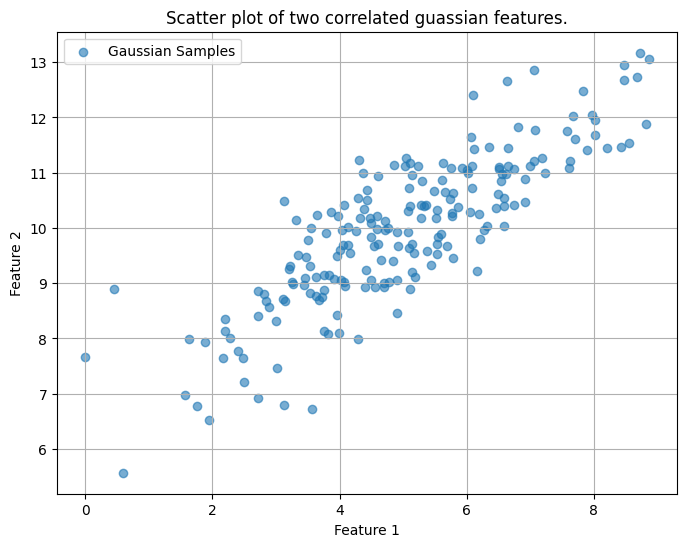


Correlation Matrix:
[[1.         0.83824583]
 [0.83824583 1.        ]]

Karl Pearson Correlation Coefficient: 0.8382

Hence, verified that the two guassian features are positively correlated.


In [ ]:
# generate and visualize the dataset.
# the same dataset will be used in the Q3 and Q4
data = generate_dataset(num_samples=200, random_seed=42)
visualize_dataset(data)

**Q3 (10 points).** Implement PCA from scratch using NumPy. Follow these steps:

- Center your dataset (mean subtraction).
- Compute the covariance matrix.
- Find eigenvalues and eigenvectors of the covariance matrix.
- Select the principal components corresponding to the highest eigenvalues.

Document each step in your implementation, linking it to your mathematical derivation from Q1. Provide visualizations of your original data along with identified principal component directions.


In [ ]:
def compute_pca(data, num_components=2):
    """
    Implements PCA (Principal Component Analysis).

    Inputs:
        data: 2D numpy array (samples x features).
        num_components: Number of principal components to retain.

    Returns:
        Dictionary containing centered data, feature means,
        covariance matrix, eigenvalues, eigenvectors, and projected data.
    """

    data = np.asarray(data, dtype=float)

    # validate input shape and number of samples.
    if data.ndim != 2:
        raise ValueError("input data must be a 2D array.")

    num_samples, num_features = data.shape

    if num_samples < 2 or num_features < 1:
        raise ValueError(
            "data must have at least 2 samples and 1 feature."
        )

    if not np.all(np.isfinite(data)):
        raise ValueError("data cannot contain NaN or infinity.")

    if not isinstance(num_components, (int, np.integer)):
        raise TypeError("num_components must be an int.")

    if not 1 <= num_components <= num_features:
        raise ValueError(
            "num_components must be between 1 and num_features."
        )

    # Step 1: center the dataset by subtracting its mean.
    feature_averages = np.mean(data, axis=0)
    centered_data = data - feature_averages

    # Step 2: calculate the sample covariance matrix.
    # Formula: Sigma = (X_centered.T @ X_centered) / (n - 1)
    covariance_matrix = (
        centered_data.T @ centered_data
    ) / (num_samples - 1)

    # Step 3: compute eigenvalues and eigenvectors.
    # np.linalg is more optimized for symmetric matrices.
    eigen_values, eigen_vectors = np.linalg.eigh(
        covariance_matrix
    )

    # Step 4: sort eigenvalues and eigenvectors together.
    sorted_indices = np.argsort(eigen_values)[::-1]
    eigen_values = eigen_values[sorted_indices]
    eigen_vectors = eigen_vectors[:, sorted_indices]

    # Step 5: select the top principal components based on num_components.
    principal_components = eigen_vectors[:, :num_components]

    # Step 6: project the centered observations onto the principal components.
    # @ is for matrix multiplication
    projected_data = centered_data @ principal_components

    return {
        "feature_averages": feature_averages,
        "centered_data": centered_data,
        "covariance_matrix": covariance_matrix,
        "eigen_values": eigen_values,
        "eigen_vectors": eigen_vectors,
        "principal_components": principal_components,
        "projected_data": projected_data
    }

In [ ]:

def plot_principal_components(data, pca_results):
    """
    Visualize the 2D dataset and principal component directions.
    """
    if data.ndim != 2 or data.shape[1] != 2:
        raise ValueError("Visualization requires 2D data.")

    feature_averages = pca_results["feature_averages"]
    eigen_values = pca_results["eigen_values"]
    eigen_vectors = pca_results["eigen_vectors"]

    # scatter plot
    plt.figure(figsize=(8, 6))
    plt.scatter(
        data[:, 0], data[:, 1],
        alpha=0.5, label="Original Data"
    )

    # initiate the arrow from dataset mean.
    # the magnitude of the arrow scales with the standard deviation.
    for component_index in range(2):
        direction = eigen_vectors[:, component_index]
        arrow_length = 2 * np.sqrt(
            max(eigen_values[component_index], 0)
        )

        # matplotlib.pyplot.quiver is optimized to visualize vectors
        plt.quiver(
            feature_averages[0],
            feature_averages[1],
            direction[0] * arrow_length,
            direction[1] * arrow_length,
            angles="xy",
            scale_units="xy",
            scale=1,
            label=f"PC{component_index + 1}"
        )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title("Original dataset with Principal Components")
    plt.axis("equal")
    plt.legend()
    plt.grid(True)
    plt.show()


In [ ]:
def calculate_explained_variance(eigenvalues):
    """
    Calculate individual and cumulative explained variance.

    Input:
        eigenvalues: Eigenvalues sorted in descending order.

    Returns:
        explained_variance_ratio: Variance fraction for each PC.
        cumulative_variance: Cumulative variance fraction.
    """
    eigenvalues = np.asarray(eigenvalues, dtype=float)

    if eigenvalues.ndim != 1 or eigenvalues.size == 0:
        raise ValueError("Eigenvalues must be a nonempty 1D array.")

    if not np.all(np.isfinite(eigenvalues)):
        raise ValueError("Eigenvalues must be finite.")

    if np.any(eigenvalues < -1e-10):
        raise ValueError("Covariance eigenvalues cannot be negative.")

    # Ignore tiny negative values caused by numerical rounding.
    eigenvalues = np.maximum(eigenvalues, 0.0)

    total_variance = np.sum(eigenvalues)

    # PCA cannot explain variance when every feature is constant.
    if total_variance <= 0:
        raise ValueError("Total variance must be positive.")

    explained_variance_ratio = eigenvalues / total_variance
    cumulative_variance = np.cumsum(explained_variance_ratio)

    return explained_variance_ratio, cumulative_variance

In [ ]:
# compute PCA.
pca_results = compute_pca(data, num_components=2)

print("Eigenvalues:")
print(pca_results["eigen_values"])

print("\nEigenvectors:")
print(pca_results["eigen_vectors"])


Eigenvalues:
[4.46070748 0.36657346]

Eigenvectors:
[[-0.79971292  0.60038259]
 [-0.60038259 -0.79971292]]


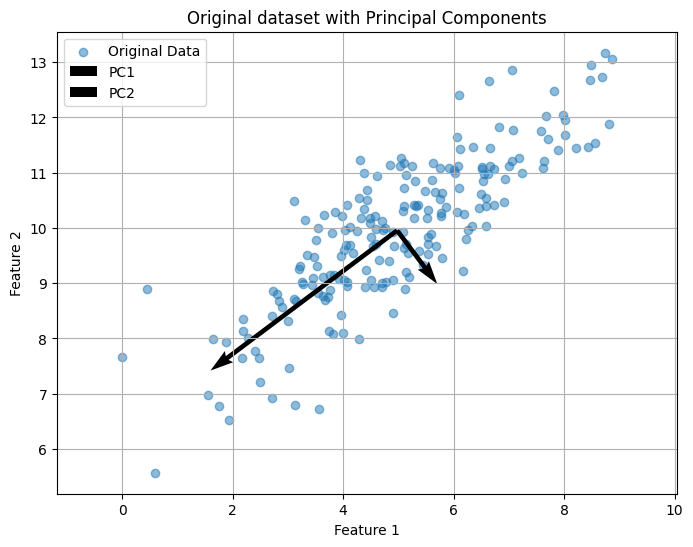

In [ ]:
# plot original observation and the principal components.
plot_principal_components(data, pca_results)

**Q4 (10 points).** Compute the proportion of total variance explained by each principal component. Discuss the results and explain the significance of dimensionality reduction. Provide insights into the trade-off between explained variance and dimensionality reduction.


In [ ]:

def plot_explained_variance(
    explained_variance_ratio, cumulative_variance
):
    """Plot variance explained by each principal component."""

    num_components = len(explained_variance_ratio)
    component_numbers = np.arange(1, num_components + 1)

    # bar plot
    plt.figure(figsize=(8, 5))
    plt.bar(
        component_numbers,
        explained_variance_ratio * 100,
        label="Individual Explained Variance"
    )

    plt.plot(
        component_numbers,
        cumulative_variance * 100,
        marker="o",
        color="red",
        label="Cumulative Explained Variance"
    )

    plt.xlabel("Principal Component")
    plt.ylabel("Explained Variance (%)")
    plt.title("Explained Variance by Principal Component")
    plt.xticks(component_numbers)
    plt.ylim(0, 110)
    plt.legend()
    plt.grid(axis="y")
    plt.show()


Explained Variance:
PC1: 92.41%
PC2: 7.59%

Cumulative Explained Variance:
PC1-PC1: 92.41%
PC1-PC2: 100.00%


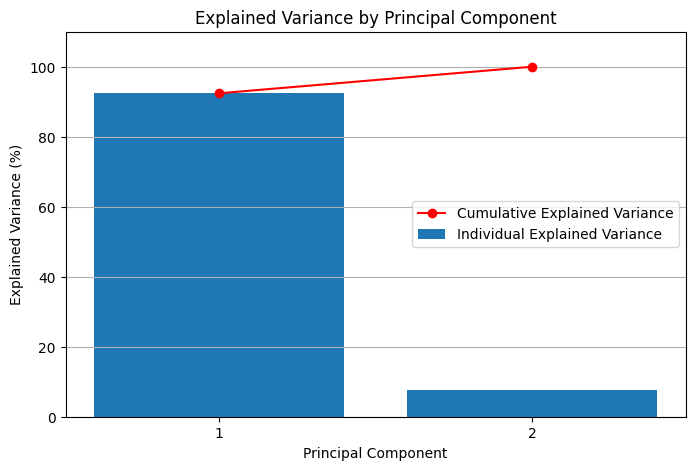

In [ ]:
variance_ratio, cumulative_variance = (
    calculate_explained_variance(
        pca_results["eigen_values"]
    )
)

print("\nExplained Variance:")
for index, ratio in enumerate(variance_ratio):
    print(f"PC{index + 1}: {ratio * 100:.2f}%")

print("\nCumulative Explained Variance:")
for index, ratio in enumerate(cumulative_variance):
    print(f"PC1-PC{index + 1}: {ratio * 100:.2f}%")

plot_explained_variance(
    variance_ratio, cumulative_variance
)


In [ ]:
# Reduce the data from 2D to 1D using PC1.
reduced_results = compute_pca(data, num_components=1)

print("\nOriginal Data Shape:", data.shape)
print("Reduced Data Shape:",
      reduced_results["projected_data"].shape)

print(
    f"Variance retained in 1D: "
    f"{variance_ratio[0] * 100:.2f}%"
)


Original Data Shape: (200, 2)
Reduced Data Shape: (200, 1)
Variance retained in 1D: 92.41%


PC1 captures 92.41% of the total variance, while PC2 amounts for rest of 7.59%.
This imbalance shows a positive correlation coefficient between the two features (r=0.83).
Dimensionality reduction successfully eliminated the feature redundancy and orthagonalized the data. This reduction significantly reduces the memory and compute consumed for further processing.

Thus, by sacrificing a small portion of our variance we achieved a siginificant simpler data representation.
